In [1]:
import pandas as pd

donnees = pd.read_csv(
    "dpe_donnees_communes.csv",
    encoding="utf-8-sig",
    dtype=str
)

print("Dimensions :", donnees.shape)
print(donnees["partition"].value_counts())

donnees.head()

Dimensions : (9921, 20)
partition
train    6915
test     3006
Name: count, dtype: int64


,numero_dpe,surface_habitable_logement,nombre_niveau_logement,surface_climatisee,code_postal_ban,type_batiment,periode_construction,type_energie_principale_chauffage,type_generateur_chauffage_principal,type_installation_chauffage,type_energie_principale_ecs,type_installation_ecs,isolation_toiture,qualite_isolation_menuiseries,type_ventilation,logement_traversant,etiquette_dpe,conso_5_usages_ef,groupe_batiment,partition
0,2669E0027508W,37.5,1,NaN,69008,appartement,2013-2021,Gaz naturel,Chaudière gaz standard après 2015,collectif,Gaz naturel,collectif,0,très bonne,NaN,0,C,2439.8,0,train
1,2669E0062001N,67.5,1,NaN,69008,appartement,1989-2000,Gaz naturel,Chaudière gaz standard 1991-2000,individuel,Gaz naturel,individuel,1,très bonne,NaN,0,C,8350.3,1,train
2,2669E0019280K,42.0,1,NaN,69007,appartement,avant 1948,Électricité,"Panneau rayonnant électrique NFC, NF** et NF***",individuel,Électricité,individuel,0,bonne,NaN,0,D,4054.5,2,train
3,2669E0045216Y,55.0,1,NaN,69006,appartement,1983-1988,Électricité,Radiateur électrique à accumulation,individuel,Électricité,individuel,0,moyenne,NaN,0,C,4359.7,3,train
4,2669E0070375P,47.8,1,NaN,69009,appartement,avant 1948,Électricité,"Convecteur électrique NFC, NF** et NF***",individuel,Électricité,individuel,0,insuffisante,NaN,0,D,5971.8,4,train


In [2]:
cible_regression = "conso_5_usages_ef"

donnees[cible_regression] = pd.to_numeric(
    donnees[cible_regression],
    errors="coerce"
)

df_ridge = donnees.loc[
    donnees[cible_regression].notna()
].copy()

df_train_ridge = df_ridge.loc[
    df_ridge["partition"].eq("train")
].copy()

df_test_ridge = df_ridge.loc[
    df_ridge["partition"].eq("test")
].copy()

print("Cible :", cible_regression)
print("Train :", len(df_train_ridge))
print("Test :", len(df_test_ridge))
print("Cibles manquantes exclues :", len(donnees) - len(df_ridge))

Cible : conso_5_usages_ef
Train : 6914
Test : 3006
Cibles manquantes exclues : 1


In [3]:
variables_numeriques = [
    "surface_habitable_logement",
    "nombre_niveau_logement",
    "surface_climatisee"
]

variables_categorielles = [
    "code_postal_ban",
    "type_batiment",
    "periode_construction",
    "type_energie_principale_chauffage",
    "type_generateur_chauffage_principal",
    "type_installation_chauffage",
    "type_energie_principale_ecs",
    "type_installation_ecs",
    "isolation_toiture",
    "qualite_isolation_menuiseries",
    "type_ventilation",
    "logement_traversant"
]

variables_explicatives = (
    variables_numeriques + variables_categorielles
)

X_train_ridge = df_train_ridge[variables_explicatives].copy()
X_test_ridge = df_test_ridge[variables_explicatives].copy()

y_train_ridge = df_train_ridge[cible_regression].copy()
y_test_ridge = df_test_ridge[cible_regression].copy()

for colonne in variables_numeriques:
    X_train_ridge[colonne] = pd.to_numeric(
        X_train_ridge[colonne],
        errors="coerce"
    )
    X_test_ridge[colonne] = pd.to_numeric(
        X_test_ridge[colonne],
        errors="coerce"
    )

print("X train :", X_train_ridge.shape)
print("X test :", X_test_ridge.shape)
print("y train :", y_train_ridge.shape)
print("y test :", y_test_ridge.shape)

print("\nValeurs manquantes — train :")
print(X_train_ridge.isna().sum())

X train : (6914, 15)
X test : (3006, 15)
y train : (6914,)
y test : (3006,)

Valeurs manquantes — train :
surface_habitable_logement               37
nombre_niveau_logement                    0
surface_climatisee                     6787
code_postal_ban                           0
type_batiment                             0
periode_construction                      0
type_energie_principale_chauffage         0
type_generateur_chauffage_principal    4856
type_installation_chauffage             182
type_energie_principale_ecs               0
type_installation_ecs                   182
isolation_toiture                      4790
qualite_isolation_menuiseries             0
type_ventilation                       5426
logement_traversant                    4790
dtype: int64


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

traitement_numerique_ridge = Pipeline([
    ("imputation", SimpleImputer(strategy="median")),
    ("standardisation", StandardScaler())
])

traitement_categoriel_ridge = Pipeline([
    (
        "imputation",
        SimpleImputer(
            strategy="constant",
            fill_value="Non_renseigne"
        )
    ),
    ("encodage", OneHotEncoder(handle_unknown="ignore"))
])

preparation_ridge = ColumnTransformer([
    (
        "numerique",
        traitement_numerique_ridge,
        variables_numeriques
    ),
    (
        "categoriel",
        traitement_categoriel_ridge,
        variables_categorielles
    )
])

modele_ridge = Pipeline([
    ("preparation", preparation_ridge),
    ("modele", Ridge(alpha=1.0, solver="lsqr"))
])

modele_ridge.fit(X_train_ridge, y_train_ridge)

print("Modèle Ridge entraîné.")
print("Alpha initial :", modele_ridge.named_steps["modele"].alpha)

Modèle Ridge entraîné.
Alpha initial : 1.0


In [5]:
from sklearn.model_selection import GroupKFold

groupes_train_ridge = df_train_ridge.loc[
    X_train_ridge.index,
    "groupe_batiment"
]

validation_ridge = GroupKFold(n_splits=3)

plis_ridge = list(
    validation_ridge.split(
        X_train_ridge,
        y_train_ridge,
        groups=groupes_train_ridge
    )
)

for numero, (indices_apprentissage, indices_validation) in enumerate(
    plis_ridge,
    start=1
):
    groupes_apprentissage = set(
        groupes_train_ridge.iloc[indices_apprentissage]
    )
    groupes_validation = set(
        groupes_train_ridge.iloc[indices_validation]
    )

    print(
        f"Pli {numero} : "
        f"train={len(indices_apprentissage)}, "
        f"validation={len(indices_validation)}, "
        f"groupes communs="
        f"{len(groupes_apprentissage & groupes_validation)}"
    )
    

Pli 1 : train=4609, validation=2305, groupes communs=0
Pli 2 : train=4609, validation=2305, groupes communs=0
Pli 3 : train=4610, validation=2304, groupes communs=0


In [6]:
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_validate

modele_reference_ridge = clone(modele_ridge).set_params(
    modele=DummyRegressor(strategy="mean")
)

mesures_regression = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

modeles_regression = {
    "Référence moyenne": modele_reference_ridge,
    "Ridge initial": modele_ridge
}

scores_cv_ridge = {}
lignes_resultats = []

for nom, modele in modeles_regression.items():
    scores = cross_validate(
        modele,
        X_train_ridge,
        y_train_ridge,
        cv=plis_ridge,
        scoring=mesures_regression,
        n_jobs=1,
        error_score="raise"
    )

    scores_cv_ridge[nom] = scores

    lignes_resultats.append({
        "Modèle": nom,
        "MAE": -scores["test_MAE"].mean(),
        "RMSE": -scores["test_RMSE"].mean(),
        "RMSE_std": scores["test_RMSE"].std(),
        "R2": scores["test_R2"].mean()
    })

comparaison_ridge = pd.DataFrame(
    lignes_resultats
).set_index("Modèle")

display(comparaison_ridge.round(3))

,MAE,RMSE,RMSE_std,R2
Modèle,,,,
Référence moyenne,5257.371,7987.369,702.782,-0.002
Ridge initial,3151.681,4681.295,162.413,0.649


In [7]:
from sklearn.model_selection import GridSearchCV

grille_ridge = {
    "modele__alpha": [
        0.01,
        0.1,
        1,
        10,
        100,
        1000
    ]
}

recherche_ridge = GridSearchCV(
    estimator=clone(modele_ridge),
    param_grid=grille_ridge,
    scoring=mesures_regression,
    refit="RMSE",
    cv=plis_ridge,
    n_jobs=1,
    verbose=1,
    error_score="raise"
)

recherche_ridge.fit(
    X_train_ridge,
    y_train_ridge
)

print("Meilleurs paramètres :")
print(recherche_ridge.best_params_)

print("\nMeilleur RMSE moyen :")
print(round(-recherche_ridge.best_score_, 3))

resultats_recherche_ridge = pd.DataFrame(
    recherche_ridge.cv_results_
)

tableau_recherche_ridge = pd.DataFrame({
    "alpha": resultats_recherche_ridge["param_modele__alpha"],
    "MAE": -resultats_recherche_ridge["mean_test_MAE"],
    "RMSE": -resultats_recherche_ridge["mean_test_RMSE"],
    "RMSE_std": resultats_recherche_ridge["std_test_RMSE"],
    "R2": resultats_recherche_ridge["mean_test_R2"]
}).sort_values("RMSE")

display(tableau_recherche_ridge.round(3))

modele_ridge_selectionne = recherche_ridge.best_estimator_

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Meilleurs paramètres :
{'modele__alpha': 10}

Meilleur RMSE moyen :
4678.431


,alpha,MAE,RMSE,RMSE_std,R2
3,10.00,3134.495,4678.431,191.863,0.649
2,1.00,3151.681,4681.295,162.413,0.649
0,0.01,3155.126,4683.322,161.762,0.649
1,0.10,3154.499,4683.332,161.003,0.649
4,100.00,3105.811,4697.344,208.519,0.646
5,1000.00,3209.829,5004.914,267.980,0.602


In [8]:
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

y_pred_test_ridge = modele_ridge_selectionne.predict(
    X_test_ridge
)

resultats_test_ridge = pd.DataFrame([{
    "Modèle": "Ridge",
    "Alpha": recherche_ridge.best_params_["modele__alpha"],
    "RMSE": np.sqrt(
        mean_squared_error(y_test_ridge, y_pred_test_ridge)
    ),
    "MAE": mean_absolute_error(
        y_test_ridge,
        y_pred_test_ridge
    ),
    "R2": r2_score(
        y_test_ridge,
        y_pred_test_ridge
    )
}])

print("Évaluation — jeu de test")
display(resultats_test_ridge.round(3))

predictions_test_ridge = pd.DataFrame({
    "numero_dpe": df_test_ridge.loc[
        X_test_ridge.index,
        "numero_dpe"
    ],
    "consommation_observee": y_test_ridge,
    "consommation_predite": y_pred_test_ridge
})

predictions_test_ridge["erreur"] = (
    predictions_test_ridge["consommation_predite"]
    - predictions_test_ridge["consommation_observee"]
)

display(predictions_test_ridge.head(10).round(2))

print(
    "Nombre de prédictions négatives :",
    int((y_pred_test_ridge < 0).sum())
)

Évaluation — jeu de test


,Modèle,Alpha,RMSE,MAE,R2
0,Ridge,10,8120.91,3012.212,0.333


,numero_dpe,consommation_observee,consommation_predite,erreur
8,2669E0050918G,3230.4,4990.26,1759.86
14,2669E0011626A,12840.2,16504.78,3664.58
15,2669E0010326A,7648.2,8704.59,1056.39
17,2669E0013614M,7641.8,5016.59,-2625.21
18,2669E0050535N,3244.9,5006.57,1761.67
20,2669E0075265R,8355.0,18880.16,10525.16
24,2669E0062799F,3175.9,3812.67,636.77
27,2669E0029765R,26070.3,33204.23,7133.93
28,2669E0050303P,2604.5,3995.12,1390.62
31,2669E0042689T,4601.8,5178.38,576.58


Nombre de prédictions négatives : 141


In [9]:
diagnostic_ridge = predictions_test_ridge.copy()

diagnostic_ridge["erreur_absolue"] = (
    diagnostic_ridge["erreur"].abs()
)

diagnostic_ridge["erreur_carree"] = (
    diagnostic_ridge["erreur"] ** 2
)

diagnostic_ridge = diagnostic_ridge.join(
    X_test_ridge[
        [
            "surface_habitable_logement",
            "type_batiment",
            "periode_construction"
        ]
    ]
)

diagnostic_ridge = diagnostic_ridge.sort_values(
    "erreur_absolue",
    ascending=False
)

print("Les 10 erreurs les plus importantes :")

display(
    diagnostic_ridge[
        [
            "numero_dpe",
            "type_batiment",
            "surface_habitable_logement",
            "consommation_observee",
            "consommation_predite",
            "erreur_absolue"
        ]
    ].head(10).round(2)
)

part_erreur_top10 = (
    diagnostic_ridge["erreur_carree"].head(10).sum()
    / diagnostic_ridge["erreur_carree"].sum()
)

print(
    "\nPart des 10 plus grandes erreurs "
    "dans la somme des erreurs au carré :",
    f"{part_erreur_top10:.1%}"
)

print("\nDistribution de la consommation observée :")

display(
    pd.DataFrame({
        "train": y_train_ridge.describe(
            percentiles=[0.5, 0.9, 0.99]
        ),
        "test": y_test_ridge.describe(
            percentiles=[0.5, 0.9, 0.99]
        )
    }).round(2)
)



Les 10 erreurs les plus importantes :


,numero_dpe,type_batiment,surface_habitable_logement,consommation_observee,consommation_predite,erreur_absolue
8413,2169E0807345K,appartement,45.0,380161.3,11324.57,368836.73
3452,2169E0201381C,appartement,79.2,141855.7,13827.60,128028.10
5314,2169E0160169A,maison,250.0,70138.0,40721.55,29416.45
4055,2169E0361743W,appartement,79.5,3267.2,-23899.25,27166.45
6458,2169E0718347K,maison,500.0,61880.4,86482.18,24601.78
5248,2169E0166411C,appartement,74.3,39933.9,16653.97,23279.93
6417,2169E0379282L,appartement,103.8,38339.9,16831.73,21508.17
2816,2169E0206291Y,appartement,234.2,60248.3,39992.46,20255.84
3038,2169E0735411S,appartement,173.8,2749.5,22911.49,20161.99
4436,2169E0511609Y,appartement,129.2,2181.5,21059.76,18878.26



Part des 10 plus grandes erreurs dans la somme des erreurs au carré : 79.1%

Distribution de la consommation observée :


,train,test
count,6914.00,3006.00
mean,9059.10,8475.10
std,8015.30,9947.73
min,164.40,432.80
50%,6911.60,6096.45
90%,17927.59,17101.80
99%,37871.87,33575.96
max,248197.60,380161.30


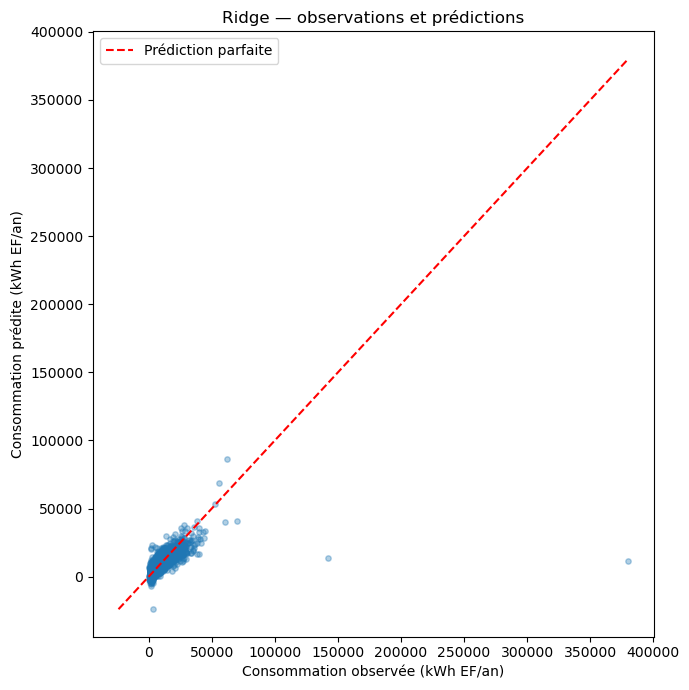

In [10]:
import matplotlib.pyplot as plt

borne_min = min(
    y_test_ridge.min(),
    y_pred_test_ridge.min()
)

borne_max = max(
    y_test_ridge.max(),
    y_pred_test_ridge.max()
)

fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(
    y_test_ridge,
    y_pred_test_ridge,
    alpha=0.35,
    s=15
)

ax.plot(
    [borne_min, borne_max],
    [borne_min, borne_max],
    color="red",
    linestyle="--",
    label="Prédiction parfaite"
)

ax.set_xlabel("Consommation observée (kWh EF/an)")
ax.set_ylabel("Consommation prédite (kWh EF/an)")
ax.set_title("Ridge — observations et prédictions")
ax.legend()

fig.tight_layout()
fig.savefig(
    "ridge_observations_predictions.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

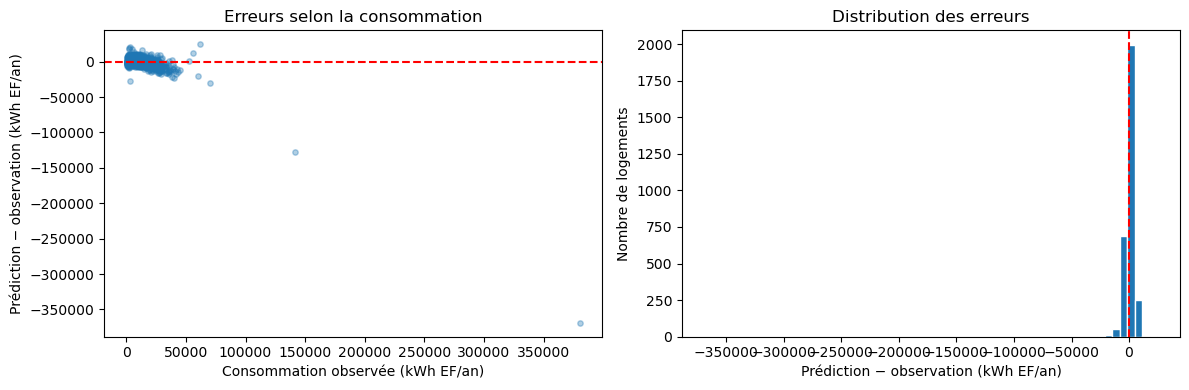

In [11]:
erreurs_test_ridge = (
    y_pred_test_ridge - y_test_ridge.to_numpy()
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4)
)

axes[0].scatter(
    y_test_ridge,
    erreurs_test_ridge,
    alpha=0.35,
    s=15
)

axes[0].axhline(
    0,
    color="red",
    linestyle="--"
)

axes[0].set_xlabel("Consommation observée (kWh EF/an)")
axes[0].set_ylabel("Prédiction − observation (kWh EF/an)")
axes[0].set_title("Erreurs selon la consommation")

axes[1].hist(
    erreurs_test_ridge,
    bins=60,
    edgecolor="white"
)

axes[1].axvline(
    0,
    color="red",
    linestyle="--"
)

axes[1].set_xlabel("Prédiction − observation (kWh EF/an)")
axes[1].set_ylabel("Nombre de logements")
axes[1].set_title("Distribution des erreurs")

fig.tight_layout()
fig.savefig(
    "ridge_diagnostic_erreurs.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [12]:
ligne_cv = tableau_recherche_ridge.iloc[0]

bilan_ridge = pd.DataFrame([
    {
        "Modèle": "Ridge",
        "Évaluation": "Validation croisée — train",
        "Alpha": recherche_ridge.best_params_["modele__alpha"],
        "RMSE": ligne_cv["RMSE"],
        "MAE": ligne_cv["MAE"],
        "R2": ligne_cv["R2"]
    },
    {
        "Modèle": "Ridge",
        "Évaluation": "Test",
        "Alpha": recherche_ridge.best_params_["modele__alpha"],
        "RMSE": resultats_test_ridge.iloc[0]["RMSE"],
        "MAE": resultats_test_ridge.iloc[0]["MAE"],
        "R2": resultats_test_ridge.iloc[0]["R2"]
    }
])

display(bilan_ridge.round(3))

,Modèle,Évaluation,Alpha,RMSE,MAE,R2
0,Ridge,Validation croisée — train,10,4678.431,3134.495,0.649
1,Ridge,Test,10,8120.910,3012.212,0.333


In [13]:
bilan_ridge.to_csv(
    "ridge_bilan.csv",
    index=False,
    encoding="utf-8-sig"
)

resultats_test_ridge.to_csv(
    "ridge_resultats_test.csv",
    index=False,
    encoding="utf-8-sig"
)

predictions_test_ridge.to_csv(
    "ridge_predictions_test.csv",
    index=False,
    encoding="utf-8-sig"
)

tableau_recherche_ridge.to_csv(
    "ridge_recherche_alpha.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Fichiers enregistrés :")
print("ridge_bilan.csv")
print("ridge_resultats_test.csv")
print("ridge_predictions_test.csv")
print("ridge_recherche_alpha.csv")

Fichiers enregistrés :
ridge_bilan.csv
ridge_resultats_test.csv
ridge_predictions_test.csv
ridge_recherche_alpha.csv


In [14]:
import joblib

joblib.dump(
    modele_ridge_selectionne,
    "ridge_pipeline.joblib"
)

print("Modèle enregistré : ridge_pipeline.joblib")

Modèle enregistré : ridge_pipeline.joblib


In [15]:
tableau_final_ridge = resultats_test_ridge[
    ["Modèle", "RMSE", "MAE", "R2"]
].rename(columns={"R2": "R²"})

print(
    "=== Régression "
    "(cible : conso_5_usages_ef, en kWh EF/an) ==="
)

display(
    tableau_final_ridge.style
    .format({
        "RMSE": "{:.3f}",
        "MAE": "{:.3f}",
        "R²": "{:.3f}"
    })
    .hide(axis="index")
)

tableau_final_ridge.to_csv(
    "ridge_resultats_finaux.csv",
    index=False,
    encoding="utf-8-sig"
)

=== Régression (cible : conso_5_usages_ef, en kWh EF/an) ===


Modèle,RMSE,MAE,R²
Ridge,8120.910,3012.212,0.333
